# Ad CTR Prediction with SVM

# Структура проекта

## Описание исследования

Компания Advandex занимается размещением рекламы через аукционную систему.
Для корректной работы аукциона необходимо заранее знать вероятность того, 
что пользователь кликнет по рекламному баннеру (CTR - click-through rate).

Некорректные прогнозы приводят к прямым финансовым потерям: если модель 
завышает CTR, платформа переплачивает за показы, если занижает - упускает 
выгодные аукционы. Поэтому важно не просто предсказать факт клика, но и 
получить корректно откалиброванные вероятности, которым можно доверять 
при принятии финансовых решений.

## Цель исследования

Построить модель бинарной классификации, которая предсказывает вероятность 
клика по рекламному баннеру (click = 1), и провести калибровку предсказанных 
вероятностей, чтобы они соответствовали реальной частоте кликов.

## Задачи исследования

1) Подготовка среды и загрузка данных.
2) Исследовательский анализ данных (EDA).
3) Разделение данных на обучающую и тестовую выборки.
4) Предобработка данных и построение пайплайнов.
5) Отбор признаков (фильтрационные методы и метод-обёртка).
6) Обучение базовых моделей: DummyClassifier, LogisticRegression, SVC.
7) Подбор гиперпараметров через GridSearchCV.
8) Финальная оценка модели на тестовой выборке.
9) Калибровка вероятностей и оценка её качества.
10) Финальный отчёт и выводы.
11) Сохранение модели для продакшена.

## Исходные данные

Датасет собран из систем показа рекламы и логирования взаимодействий 
пользователей с рекламными баннерами. Данные анонимизированы.

**Идентификаторы и временные метки:**
- `id` - уникальный идентификатор показа баннера.
- `hour` - час показа в формате YYMMDDHH.

**Характеристики рекламной площадки:**
- `site_id` - идентификатор веб-сайта.
- `site_domain` - домен веб-сайта.
- `site_category` - тематическая категория сайта.

**Характеристики приложения:**
- `app_id` - идентификатор мобильного приложения.
- `app_domain` - домен приложения.
- `app_category` - категория приложения.

**Характеристики устройства:**
- `device_id` - идентификатор устройства.
- `device_ip` - IP-адрес устройства.
- `device_model` - модель устройства.
- `device_type` - тип устройства (смартфон, ПК и т.д.).
- `device_conn_type` - тип соединения (Wi-Fi, 3G, 4G и т.д.).

**Параметры баннера и аукциона:**
- `banner_pos` - позиция баннера на странице.
- `C1`, `C14`–`C21` - анонимизированные признаки параметров аукциона.

**Машинно-сгенерированные признаки:**
- `ml_feature_1`, `ml_feature_3`–`ml_feature_6`, `ml_feature_8`–`ml_feature_10` - числовые признаки.
- `ml_feature_2`, `ml_feature_7` - категориальные признаки.

**Целевая переменная:**
- `click` - факт клика: 1 - клик был, 0 - клика не было.


# План исследования

- Этап 1. Подготовка среды и загрузка данных
- Этап 2. Исследовательский анализ данных (EDA)
- Этап 3. Разделение данных на выборки
- Этап 4. Предобработка данных и пайплайны
- Этап 5. Отбор признаков
- Этап 6. Базовые модели
- Этап 7. Подбор гиперпараметров
- Этап 8. Финальная модель
- Этап 9. Калибровка модели
- Этап 10. Оценка качества калибровки
- Этап 11. Финальный отчёт
- Этап 12. Сохранение модели


## 1. Подготовка среды и загрузка данных

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import phik

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, cross_val_score

from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif, RFE

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    classification_report,
    PrecisionRecallDisplay,
    make_scorer
)

import pickle, joblib

In [4]:
# настройки отображения
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.rcParams['figure.figsize'] = (10, 5)

In [5]:
# фиксируем random_state
RANDOM_SEED = 333

In [6]:
# загрузка данных
df = pd.read_csv('datasets/ds_s16_ad_click_dataset.csv')
df.shape

(50000, 34)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 34 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                50000 non-null  float64
 1   click             50000 non-null  int64  
 2   hour              50000 non-null  int64  
 3   C1                50000 non-null  int64  
 4   banner_pos        50000 non-null  int64  
 5   site_id           50000 non-null  object 
 6   site_domain       50000 non-null  object 
 7   site_category     50000 non-null  object 
 8   app_id            50000 non-null  object 
 9   app_domain        50000 non-null  object 
 10  app_category      50000 non-null  object 
 11  device_id         50000 non-null  object 
 12  device_ip         50000 non-null  object 
 13  device_model      50000 non-null  object 
 14  device_type       50000 non-null  int64  
 15  device_conn_type  50000 non-null  int64  
 16  C14               50000 non-null  int64 

In [8]:
df.head()

,id,click,hour,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,app_category,device_id,device_ip,device_model,device_type,device_conn_type,C14,C15,C16,C17,C18,C19,C20,C21,ml_feature_1,ml_feature_2,ml_feature_3,ml_feature_4,ml_feature_5,ml_feature_6,ml_feature_7,ml_feature_8,ml_feature_9,ml_feature_10
0,10052627552648869888.0000,1,14102100,1005,1,d9750ee7,98572c79,f028772b,ecad2386,7801e8d9,07d7df22,a99f214a,488a9a3e,31025cda,1,0,17614,320,50,1993,2,1063,-1,33,-0.9968,A,0.6666,0,0.8173,0.9933,Z,-0.6200,0.4337,0.2740
1,10105971003478261760.0000,0,14102100,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,07d7df22,a99f214a,75bb1b58,2ee63ff8,1,0,15701,320,50,1722,0,35,-1,79,-0.3913,C,5.1468,1,-0.8839,-0.8257,X,0.5765,-0.3186,-0.1329
2,10120475683957065728.0000,0,14102100,1005,0,d9750ee7,98572c79,f028772b,ecad2386,7801e8d9,07d7df22,a99f214a,285263b0,d780319b,1,0,17914,320,50,2043,2,39,100084,32,-2.1127,D,7.1693,0,-0.8594,-0.3384,Y,-0.4400,-0.3454,0.3405
3,1021995395003627776.0000,0,14102100,1005,0,85f751fd,c4e18dd6,50e219e0,39cfef32,d9b5648e,0f2161f8,a99f214a,18190986,f4fffcd0,1,0,21611,320,50,2480,3,297,100111,61,0.3327,A,-0.2907,1,0.0628,0.0629,Y,0.5520,0.7334,-0.1985
4,10234552355176744960.0000,0,14102100,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,07d7df22,a99f214a,b66e5482,a0f5f879,1,0,15702,320,50,1722,0,35,100084,79,1.1666,A,6.3191,1,-0.6753,0.7971,X,0.6408,0.2980,-0.1369


## 2. Исследовательский анализ данных (EDA)

***1) Базовая информация:***

В датасете 50 000 записей и 34 признака. Каждая строка - один уникальный показ рекламного баннера. Признаки уже подготовлены: есть числовые (ml_feature_*) и категориальные (site_id, device_model и т.д.), а также анонимизированные параметры аукциона (C1, C14–C21).

***2) Анализ целевой переменной:***

In [9]:
# распределение целевой переменной
print(df['click'].value_counts(), df['click'].value_counts(normalize=True).round(4), sep='\n')

click
0    41397
1     8603
Name: count, dtype: int64
click
0   0.8279
1   0.1721
Name: proportion, dtype: float64


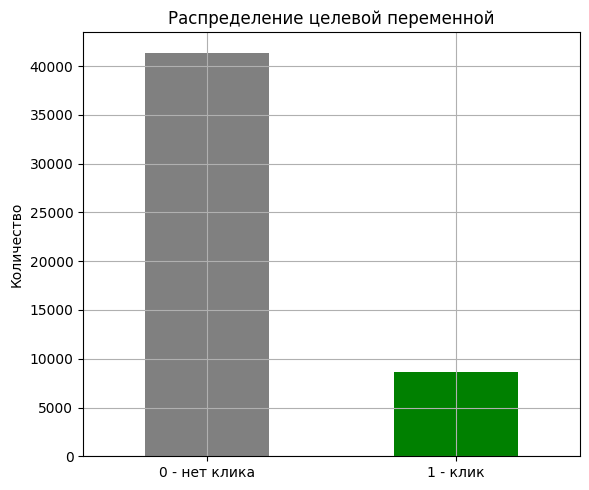

In [10]:
counts = df['click'].value_counts().sort_index()
counts.index = ['0 - нет клика', '1 - клик']

counts.plot(kind='bar', color=['gray', 'green'], figsize=(6, 5))
plt.title('Распределение целевой переменной')
plt.ylabel('Количество')
plt.grid()
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Наблюдается дисбаланс классов: кликов всего ~17%, остальные 83% - показы без клика. Из-за этого accuracy не подходит в качестве метрики - модель могла бы просто предсказывать 0 и получать 82% без всякой пользы. Основная метрика - PR-AUC.

***3) Анализ признаков:***

In [11]:
# смотрим количество уникальных значений по каждому столбцу
df.nunique().sort_values()

ml_feature_4            2
click                   2
ml_feature_7            3
device_conn_type        4
device_type             4
C18                     4
ml_feature_2            5
C1                      7
banner_pos              7
C15                     8
C16                     9
site_category          18
app_category           22
C21                    59
C19                    64
app_domain             67
C20                   149
hour                  240
C17                   387
app_id                976
site_domain          1013
site_id              1160
C14                  1497
device_model         2521
device_id            8580
device_ip           41455
ml_feature_6        50000
ml_feature_8        50000
id                  50000
ml_feature_3        50000
ml_feature_1        50000
ml_feature_9        50000
ml_feature_5        50000
ml_feature_10       50000
dtype: int64

Признак id - уникальный идентификатор каждого показа, для модели бесполезен. Признак device_ip имеет 41 455 уникальных значений из 50 000 строк - по сути тоже идентификатор, никакой обобщающей информации не несёт. Оба удаляем.

In [12]:
df = df.drop(columns=['id', 'device_ip'])

In [13]:
# час суток из YYMMDDHH (последние 2 цифры = HH)
df['hour_of_day'] = df['hour'] % 100
df = df.drop(columns=['hour'])

# C20 содержит -1 как служебное значение - добавляем флаг
df['C20_is_neg'] = (df['C20'] < 0).astype(int)
df.loc[df['C20'] < 0, 'C20'] = 0

In [14]:
df.shape

(50000, 33)

In [15]:
# разбивка по типам данных
cat_cols = df.select_dtypes(include=['object']).columns.tolist()

print('Категориальные:', cat_cols)

Категориальные: ['site_id', 'site_domain', 'site_category', 'app_id', 'app_domain', 'app_category', 'device_id', 'device_model', 'ml_feature_2', 'ml_feature_7']


**Категориальные признаки** (object): site_id, site_domain, site_category, app_id, app_domain, app_category, device_id, device_model, ml_feature_2, ml_feature_7 - хранятся как строки. Остальные признаки числовые.

***4) Анализ пропущенных значений:***

In [16]:
df.isna().sum().sort_values(ascending=False)

click               0
C18                 0
hour_of_day         0
ml_feature_10       0
ml_feature_9        0
ml_feature_8        0
ml_feature_7        0
ml_feature_6        0
ml_feature_5        0
ml_feature_4        0
ml_feature_3        0
ml_feature_2        0
ml_feature_1        0
C21                 0
C20                 0
C19                 0
C17                 0
C1                  0
C16                 0
C15                 0
C14                 0
device_conn_type    0
device_type         0
device_model        0
device_id           0
app_category        0
app_domain          0
app_id              0
site_category       0
site_domain         0
site_id             0
banner_pos          0
C20_is_neg          0
dtype: int64

Пропусков в данных нет. Тем не менее в пайплайн добавим SimpleImputer - медиана для числовых, мода для категориальных. Это защита на случай если модель встретит пропуски в новых данных.

***5) Анализ категориальных признаков:***

In [17]:
cat_cols = df.select_dtypes(include='object').columns.tolist()

for col in cat_cols:
    print(f'{col}: {df[col].nunique()} уникальных')

site_id: 1160 уникальных
site_domain: 1013 уникальных
site_category: 18 уникальных
app_id: 976 уникальных
app_domain: 67 уникальных
app_category: 22 уникальных
device_id: 8580 уникальных
device_model: 2521 уникальных
ml_feature_2: 5 уникальных
ml_feature_7: 3 уникальных


Способы кодирования признаков:

- **One-Hot Encoding** (мало уникальных): site_category (18), app_category (22), ml_feature_2 (5), ml_feature_7 (3) - количество новых колонок будет небольшим.

- **Target Encoding** (много уникальных): site_id (1160), site_domain (1013), app_id (976), app_domain (67), device_id (8580), device_model (2521) - OHE создаст тысячи колонок, Target Encoding заменяет категорию средним значением целевой переменной.

***6) Анализ выбросов и распределений:***

In [18]:
all_num_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
df[all_num_cols].describe()

,click,C1,banner_pos,device_type,device_conn_type,C14,C15,C16,C17,C18,C19,C20,C21,ml_feature_1,ml_feature_3,ml_feature_4,ml_feature_5,ml_feature_6,ml_feature_8,ml_feature_9,ml_feature_10,hour_of_day,C20_is_neg
count,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000
mean,0.1721,1004.9701,0.2914,1.0181,0.3372,18826.6487,318.8664,59.6925,2109.7810,1.4281,227.7038,53173.8521,83.6852,-0.0024,-0.0364,0.4980,0.0347,0.0229,0.0255,0.0354,0.0202,11.2215,0.4689
std,0.3774,1.1102,0.5142,0.5385,0.8601,4983.0642,20.5615,46.7208,612.9631,1.3274,351.5921,49959.6828,70.5395,1.0003,5.7923,0.5000,1.0021,0.6567,0.5780,0.5050,0.3033,5.9380,0.4990
min,0.0000,1001.0000,0.0000,0.0000,0.0000,375.0000,120.0000,20.0000,112.0000,0.0000,33.0000,0.0000,13.0000,-4.6313,-9.9997,0.0000,-4.6319,-1.0000,-1.0000,-2.1475,-1.2880,0.0000,0.0000
25%,0.0000,1005.0000,0.0000,1.0000,0.0000,16920.0000,320.0000,50.0000,1823.0000,0.0000,35.0000,0.0000,23.0000,-0.6778,-5.0596,0.0000,-0.6398,-0.5798,-0.4706,-0.3041,-0.1824,6.0000,0.0000
50%,0.0000,1005.0000,0.0000,1.0000,0.0000,20346.0000,320.0000,50.0000,2323.0000,2.0000,39.0000,100049.0000,61.0000,-0.0038,-0.0562,0.0000,0.0281,0.0378,0.0273,0.0360,0.0189,11.0000,0.0000
75%,0.0000,1005.0000,1.0000,1.0000,0.0000,21916.0000,320.0000,50.0000,2526.0000,3.0000,171.0000,100094.0000,108.0000,0.6735,4.9859,1.0000,0.7076,0.6371,0.5211,0.3742,0.2241,16.0000,1.0000
max,1.0000,1012.0000,7.0000,5.0000,5.0000,24043.0000,1024.0000,1024.0000,2757.0000,3.0000,1839.0000,100248.0000,255.0000,3.7938,10.0000,1.0000,4.2306,1.0000,1.1199,2.1208,1.2023,23.0000,1.0000


In [19]:
float_cols = df.select_dtypes(include='float64').columns.tolist()
int_cols = df.select_dtypes(include='int64').columns.drop('click').tolist()
# целочисленные с большим числом значений - в гистограммы
int_hist = [col for col in int_cols if df[col].nunique() > 25]
# целочисленные с малым числом значений - в барплоты
int_bar = [col for col in int_cols if df[col].nunique() <= 25]

print('Гистограммы:', float_cols + int_hist)
print('Барплоты:', int_bar)

Гистограммы: ['ml_feature_1', 'ml_feature_3', 'ml_feature_5', 'ml_feature_6', 'ml_feature_8', 'ml_feature_9', 'ml_feature_10', 'C14', 'C17', 'C19', 'C20', 'C21']
Барплоты: ['C1', 'banner_pos', 'device_type', 'device_conn_type', 'C15', 'C16', 'C18', 'ml_feature_4', 'hour_of_day', 'C20_is_neg']


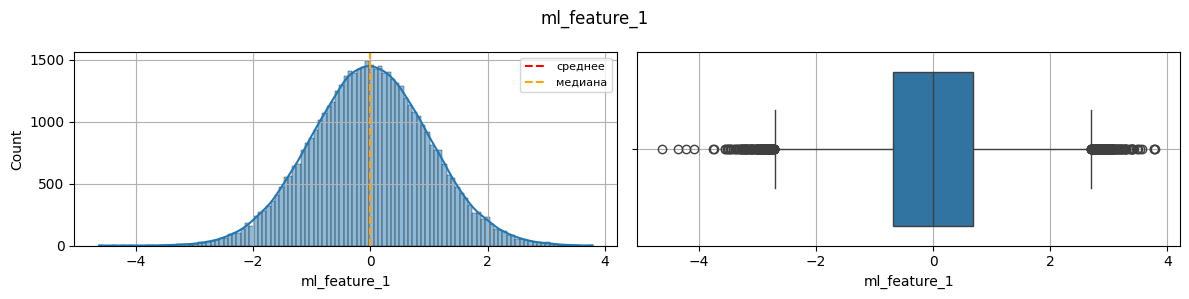

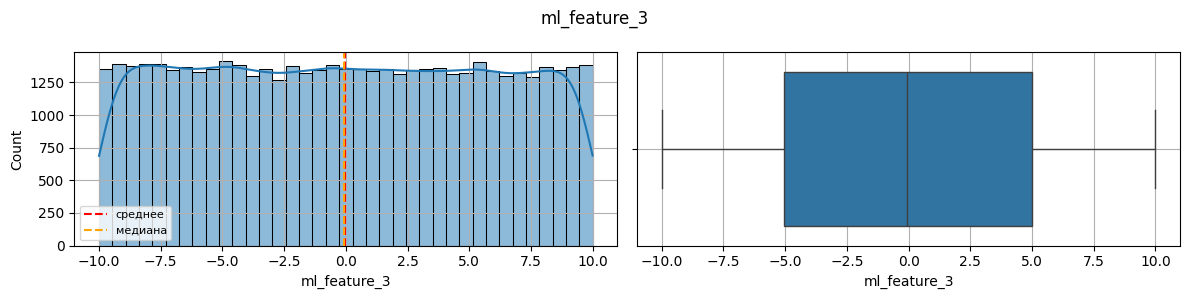

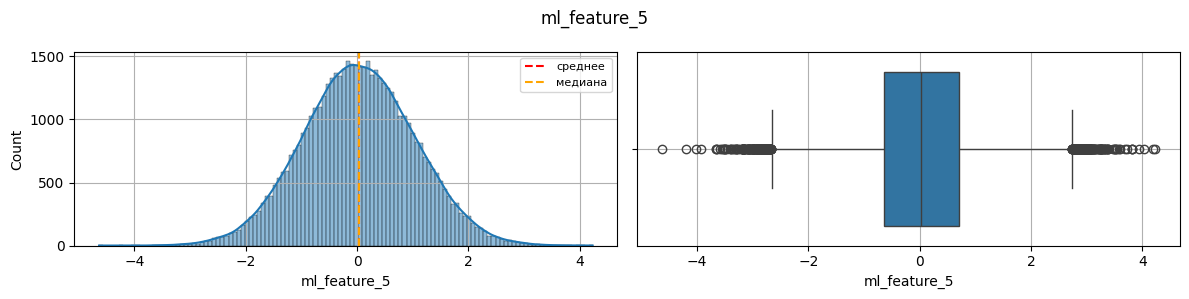

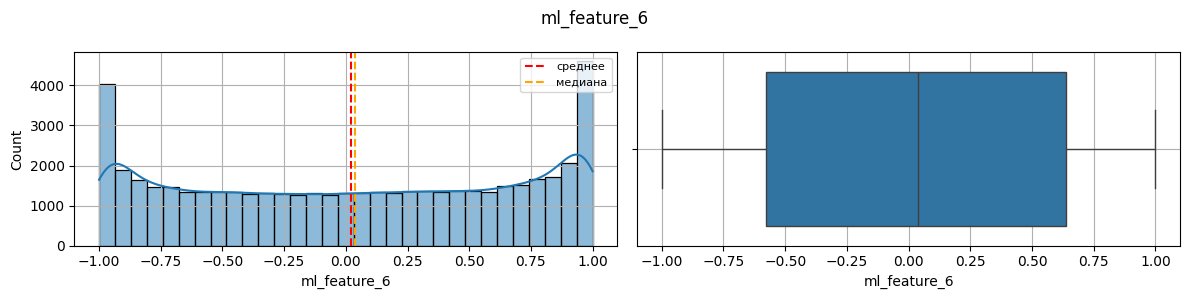

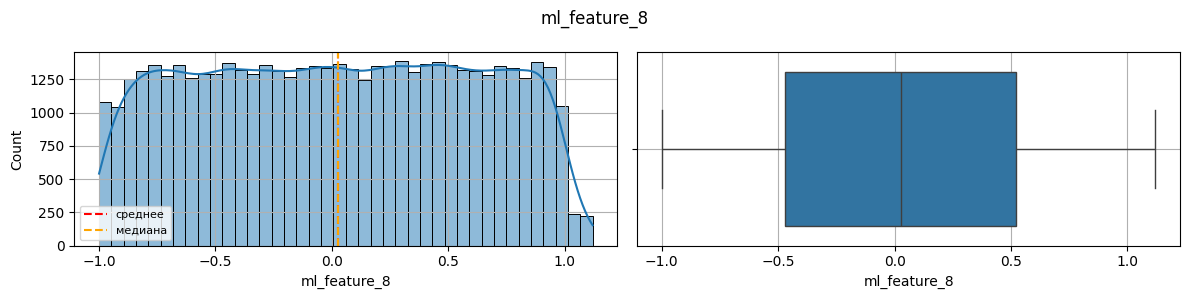

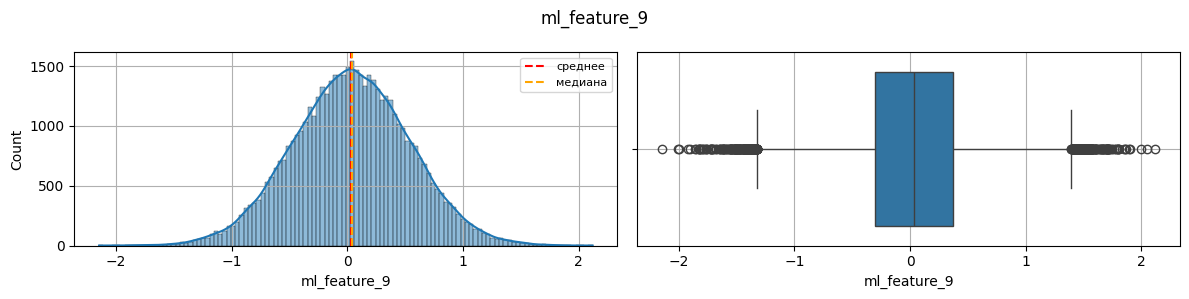

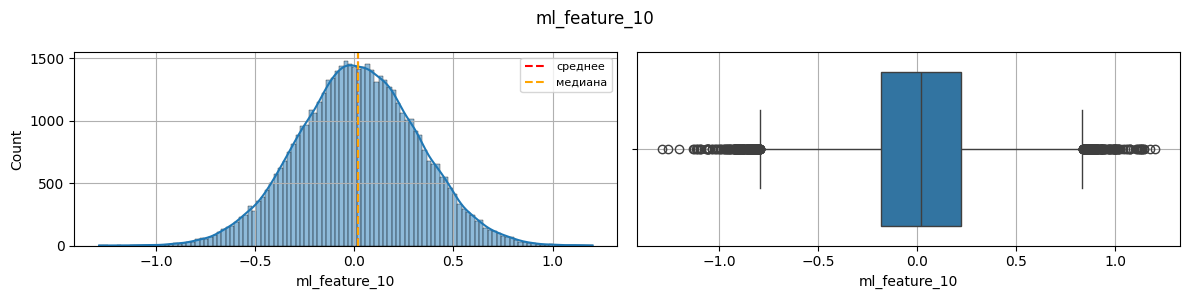

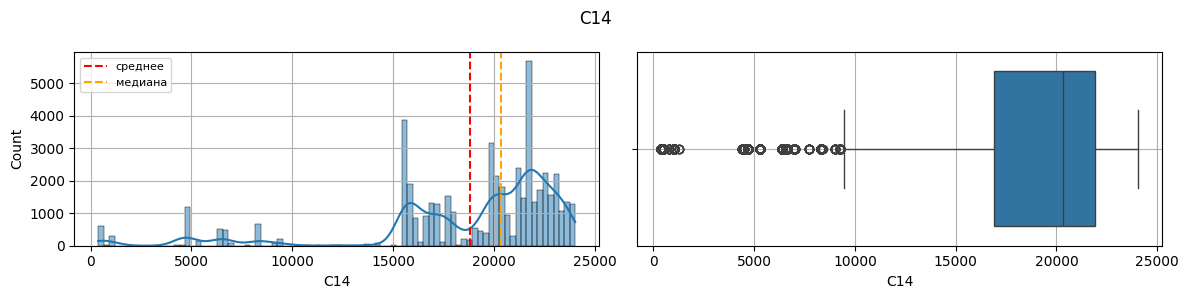

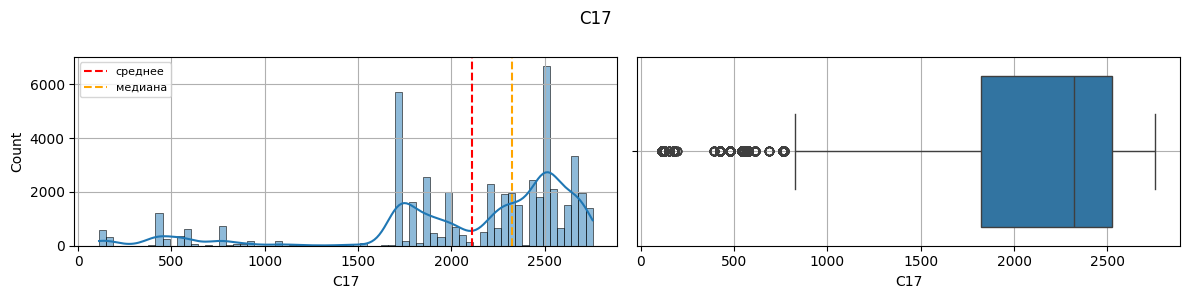

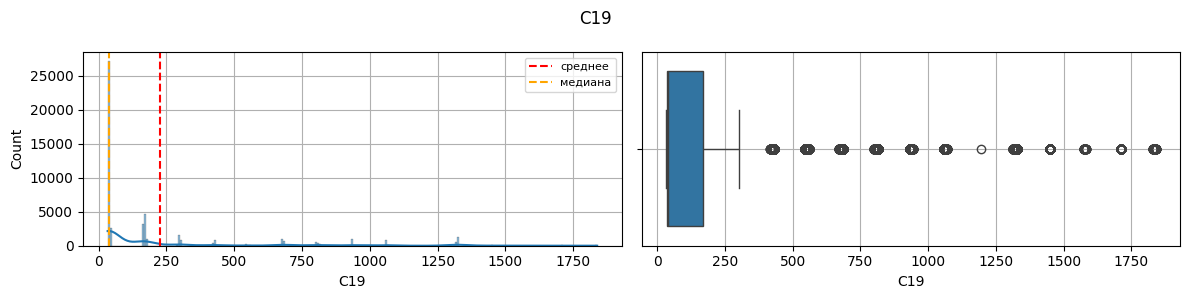

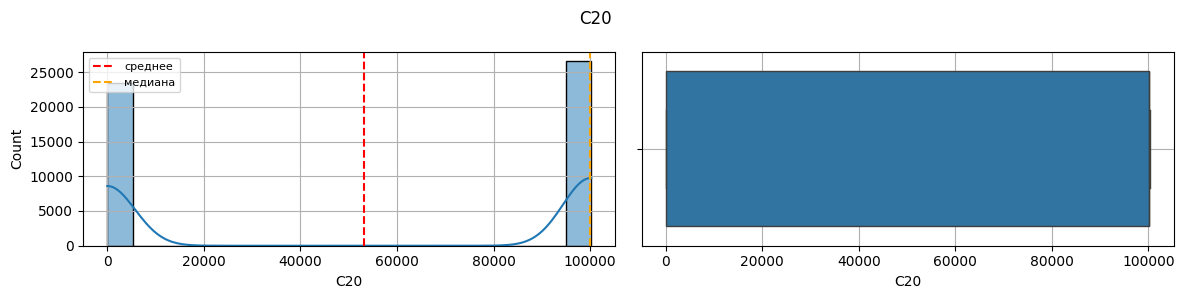

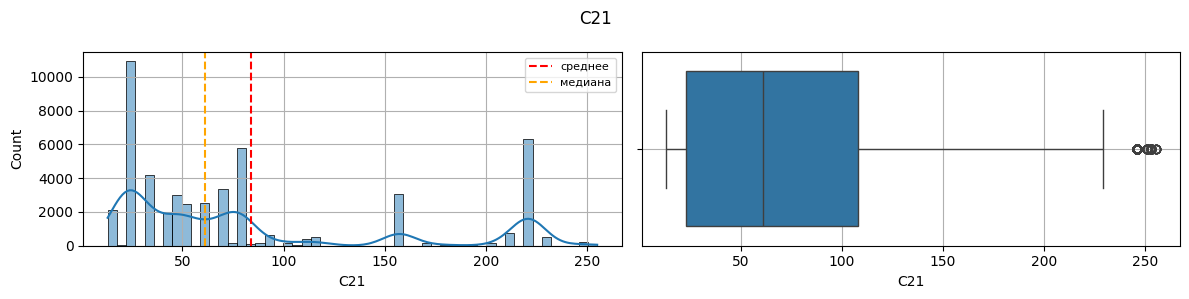

In [20]:
# гистограммы и боксплоты для непрерывных признаков для анализа выбросов и распределений
for col in float_cols + int_hist:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3))
    sns.histplot(data=df, x=col, kde=True, ax=axes[0])
    axes[0].axvline(df[col].mean(), color='red', linestyle='--', label='среднее')
    axes[0].axvline(df[col].median(), color='orange', linestyle='--', label='медиана')
    axes[0].legend(fontsize=8)
    axes[0].grid(True)
    sns.boxplot(data=df, x=col, ax=axes[1])
    axes[1].grid(True)
    plt.suptitle(col)
    plt.tight_layout()
    plt.show()

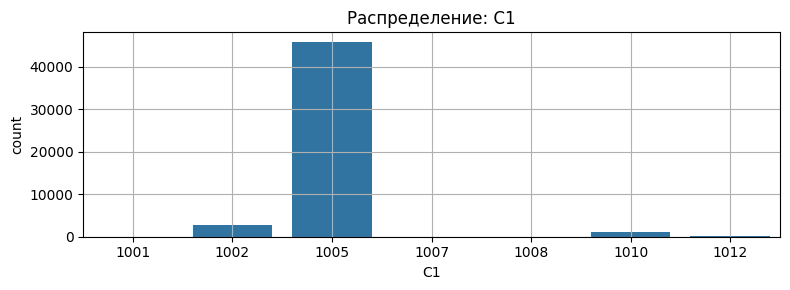

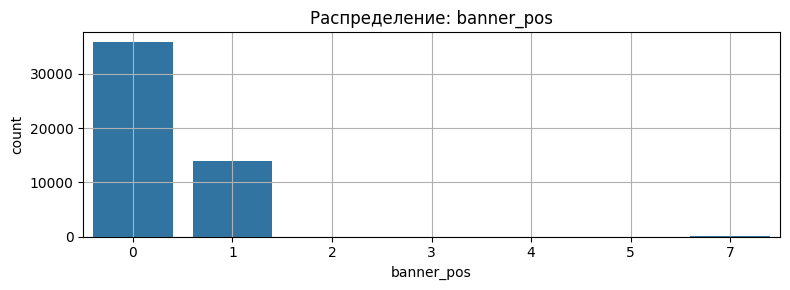

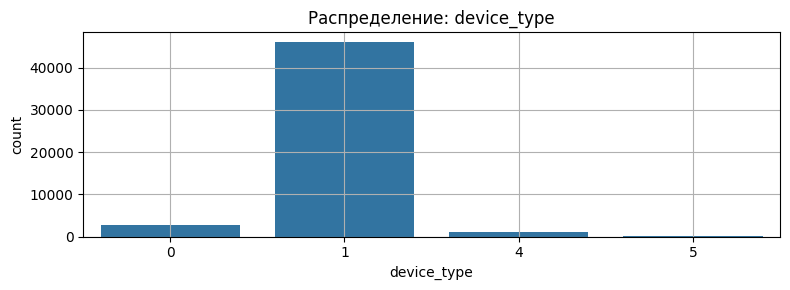

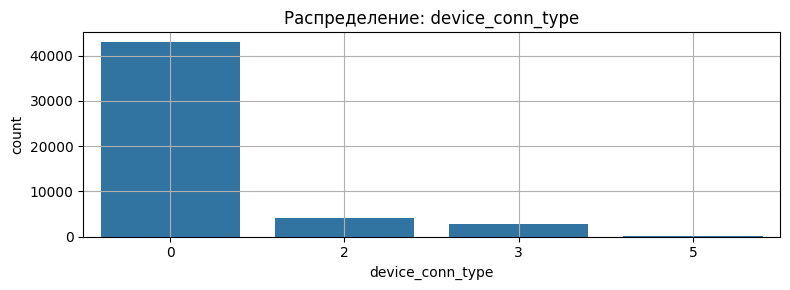

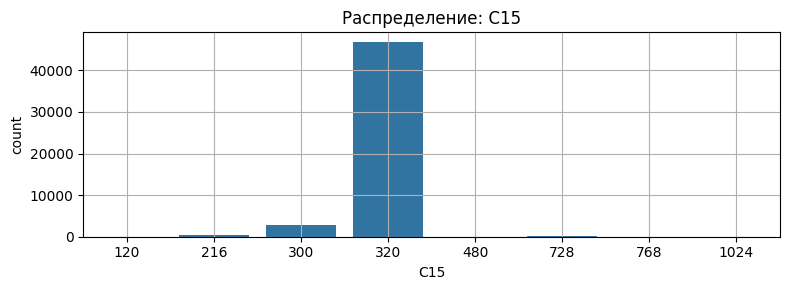

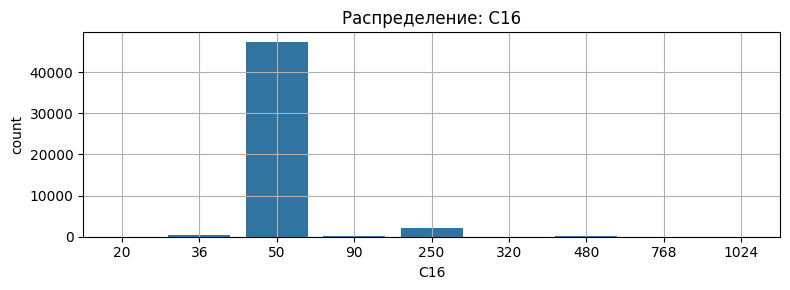

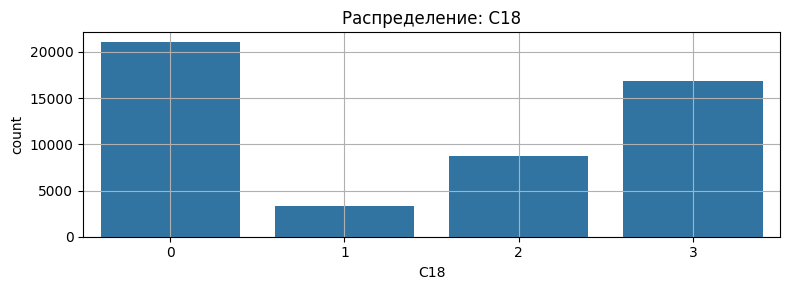

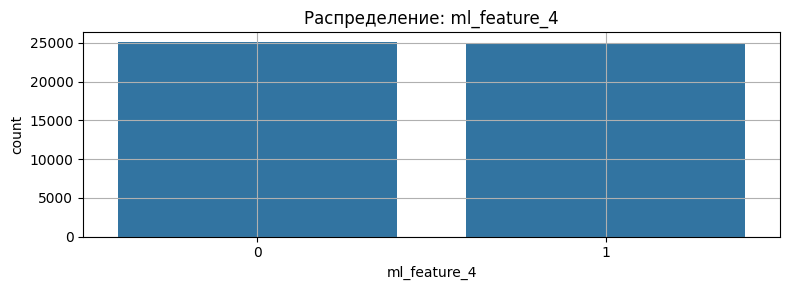

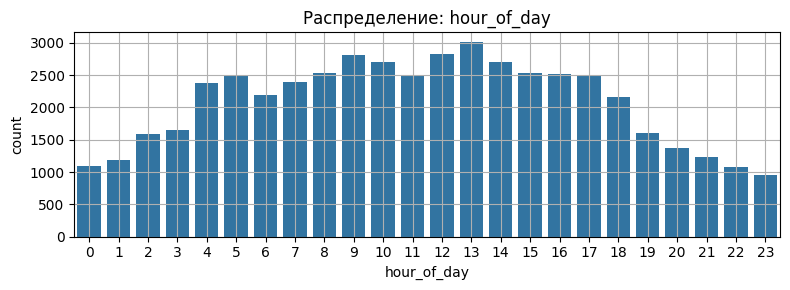

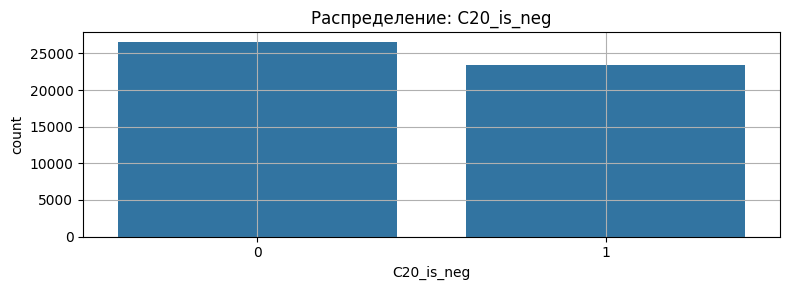

In [21]:
# барплоты для категориальных целочисленных признаков
for col in int_bar:
    plt.figure(figsize=(8, 3))
    sns.countplot(data=df, x=col)
    plt.title(f'Распределение: {col}')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

По гистограммам и боксплотам видно несколько интересных паттернов. C19 и C21 имеют сильный правый скос - большинство значений сконцентрированы в небольшом диапазоне. C20 показывает бимодальное распределение с двумя пиками около 0 и 100 000 - вероятно один из них служебное значение. C1 практически константный признак - один доминирующий бар, остальные значения встречаются редко.

Выбросы присутствуют у ряда признаков, но удалять их не будем - данные анонимизированы и природа признаков неизвестна. Финальный отбор признаков сделаем на этапе 5.

***7) Корреляции:***

In [22]:
# разделяем до анализа корреляций с целевой переменной
X = df.drop(columns=['click'])
y = df['click']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)

In [23]:
# корреляция числовых признаков с целевой переменной - только на трейне
interval_cols = ['ml_feature_1', 'ml_feature_3', 'ml_feature_5', 'ml_feature_6',
                 'ml_feature_8', 'ml_feature_9', 'ml_feature_10',
                 'C14', 'C17', 'C19', 'C20', 'C21']
num_corr = pd.concat([X_train[interval_cols], y_train], axis=1).corr()['click'].drop('click').sort_values(ascending=False)
print(num_corr.round(3))

ml_feature_9     0.1490
ml_feature_10    0.1260
ml_feature_8     0.0800
ml_feature_6     0.0730
ml_feature_5     0.0640
ml_feature_3     0.0050
ml_feature_1    -0.0020
C19             -0.0040
C20             -0.0480
C17             -0.0600
C21             -0.0640
C14             -0.0660
Name: click, dtype: float64


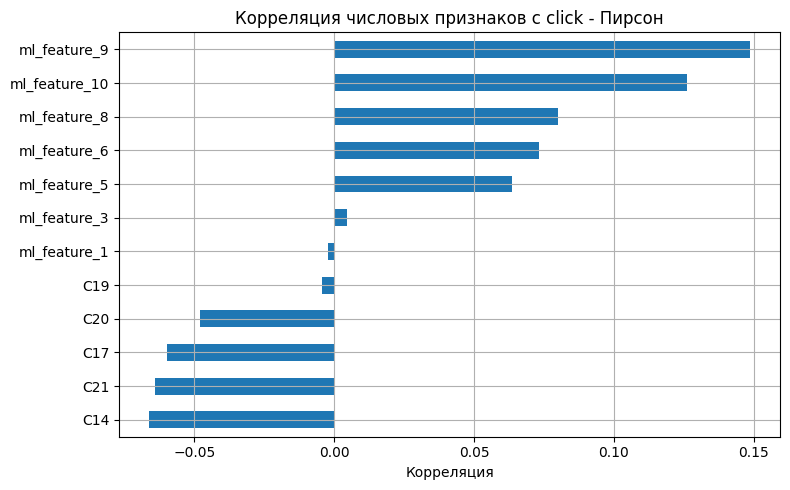

In [24]:
plt.figure(figsize=(8, 5))
num_corr.sort_values().plot(kind='barh')
plt.title('Корреляция числовых признаков с click - Пирсон')
plt.xlabel('Корреляция')
plt.grid(True)
plt.tight_layout()
plt.show()

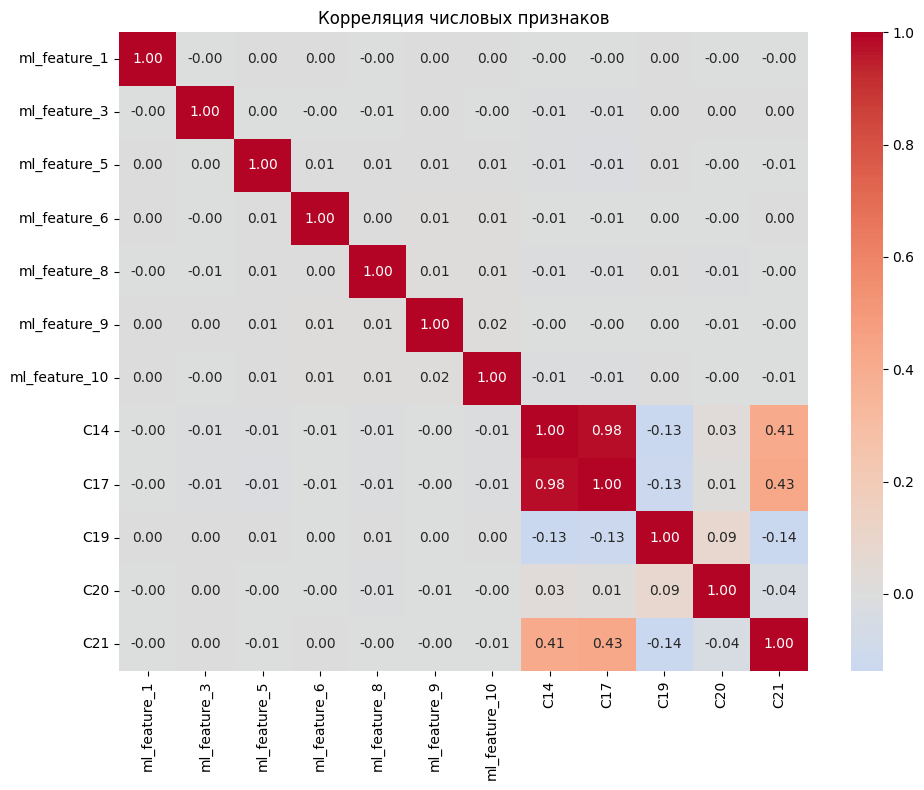

In [25]:
# тепловая карта корреляций между числовыми признаками
plt.figure(figsize=(10, 8))
sns.heatmap(df[interval_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляция числовых признаков')
plt.tight_layout()
plt.show()

По числовым признакам видно что наибольшую корреляцию с click имеют ml_feature_9 (0.149) и ml_feature_10 (0.126) - они наиболее информативны. ml_feature_1 и ml_feature_3 практически не коррелируют с целевой переменной.

Из тепловой карты видна сильная взаимная корреляция между C14 и C17 - коэффициент 0.98, что говорит о мультиколлинеарности. Один из них потенциально избыточен. C21 также умеренно коррелирует с C14 и C17.

Корреляцию категориальных признаков с целевой переменной здесь не считали - phik не справился с высококардинальными признаками по памяти. Отбор с учётом категориальных признаков проведём на этапе 5 с помощью специальных методов.

***8) Выводы по EDA:***

- Датасет содержит 50 000 записей, пропусков нет.
- Дисбаланс классов: 17.2% кликов против 82.8% - основная метрика PR-AUC.
- Удалены id и device_ip как идентификаторы, не несущие информации для модели.
- Категориальные признаки разделены на две группы: малая кардинальность - OHE и высокая - используем Target Encoding.
- Среди числовых признаков наибольшую корреляцию с click показали ml_feature_9 и ml_feature_10. ml_feature_1 и ml_feature_3 практически не коррелируют с целевой переменной.
- Обнаружена сильная взаимная корреляция между C14 и C17 (0.98), один из них потенциально избыточен.
- C1, C15, C16 доминируются одним значением - их информативность под вопросом.
- C20 имеет бимодальное распределение, C19 и C21 - сильный правый скос.
- Выбросы обрабатывать не будем, тк не знаем их природу.
- Финальный отбор признаков и работа с категориальными предстоит на этапе 5.

## 3. Разделение данных на выборки

***1) Разделение данных:***

In [26]:
X = df.drop(columns=['click'])
y = df['click']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)

***2) Проверка разделений и размеры выборок:***

In [27]:
print('Train:', y_train.value_counts(normalize=True).round(3).to_dict())
print('Test: ', y_test.value_counts(normalize=True).round(3).to_dict())

Train: {0: 0.828, 1: 0.172}
Test:  {0: 0.828, 1: 0.172}


In [28]:
# Размеры выборок
print(f'Train: {X_train.shape[0]} строк')
print(f'Test:  {X_test.shape[0]} строк')

Train: 40000 строк
Test:  10000 строк


Стратификация сохранила баланс классов в обеих выборках - доля кликов одинакова в train и test. Размеры выборок соответствуют ожидаемым значениям. Распределение сохранено.

## 4. Предобработка данных и построение пайплайнов

***1) Создание пайплайна для предобработки данных:***

In [29]:
# числовые признаки
num_features = ['ml_feature_1', 'ml_feature_3', 'ml_feature_5', 'ml_feature_6',
                'ml_feature_8', 'ml_feature_9', 'ml_feature_10',
                'C14', 'C17', 'C19', 'C20', 'C21']

# категориальные с малой кардинальностью - OHE
cat_ohe = ['site_category', 'app_category', 'ml_feature_2', 'ml_feature_7',
           'C1', 'banner_pos', 'device_type', 'device_conn_type',
           'C15', 'C16', 'C18', 'ml_feature_4',
           'hour_of_day', 'C20_is_neg']

# категориальные с высокой кардинальностью - Target Encoding
cat_te = ['site_id', 'site_domain', 'app_id', 'app_domain', 'device_id', 'device_model']

***2) Объединение пайплайнов:***

In [30]:
# пайплайн для числовых признаков
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# пайплайн для категориальных с малой кардинальностью
ohe_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# пайплайн для категориальных с высокой кардинальностью
te_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', TargetEncoder())
])

# объединяем всё в один препроцессор
preprocessor = ColumnTransformer([
    ('num', num_pipe, num_features),
    ('ohe', ohe_pipe, cat_ohe),
    ('te',  te_pipe,  cat_te)
])

Для числовых признаков используем медиану для заполнения пропусков и StandardScaler для масштабирования. Для категориальных с малой кардинальностью - OHE, с высокой - Target Encoding, который заменяет категорию средним значением целевой переменной.

## 5. Отбор признаков

***1) Фильтрационные методы:***

In [31]:
# сначала предобрабатываем тренировочные данные
X_train_proc = preprocessor.fit_transform(X_train, y_train)
X_test_proc = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
print(f'Признаков после предобработки: {X_train_proc.shape[1]}')

Признаков после предобработки: 135


In [32]:
# удаляем признаки с низкой вариацией
var_sel = VarianceThreshold(threshold=0.01)
X_train_var = var_sel.fit_transform(X_train_proc)
feature_names_var = feature_names[var_sel.get_support()]

print(f'Признаков после VarianceThreshold: {X_train_var.shape[1]}')

Признаков после VarianceThreshold: 79


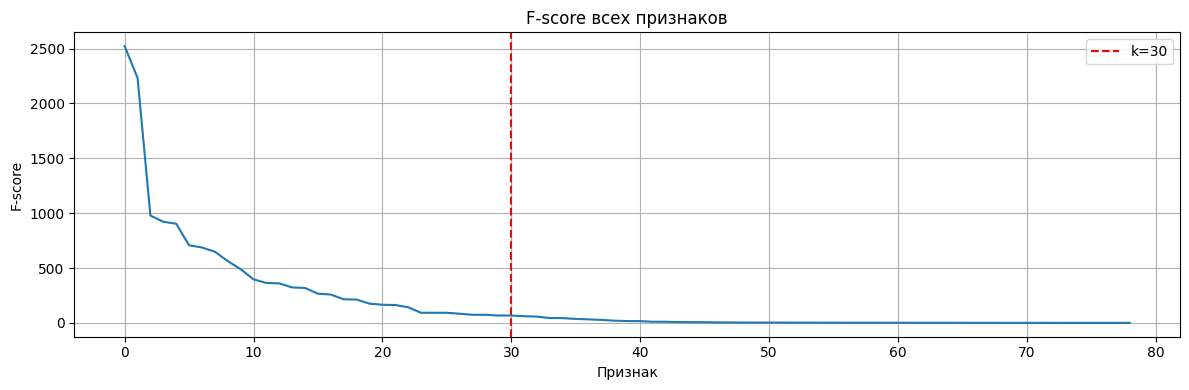

In [33]:
# все F-score после VarianceThreshold
all_scores = pd.Series(
    SelectKBest(f_classif, k='all').fit(X_train_var, y_train).scores_,
    index=feature_names_var
).sort_values(ascending=False)

plt.figure(figsize=(12, 4))
plt.plot(range(len(all_scores)), all_scores.values)
plt.axvline(x=30, color='red', linestyle='--', label='k=30')
plt.title('F-score всех признаков')
plt.xlabel('Признак')
plt.ylabel('F-score')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

По графику F-score видно резкое падение в первых признаках, после 30-го значения стремятся к нулю - дальнейшие признаки практически не несут статистически значимой связи с целевой переменной. Поэтому выберем k=30.

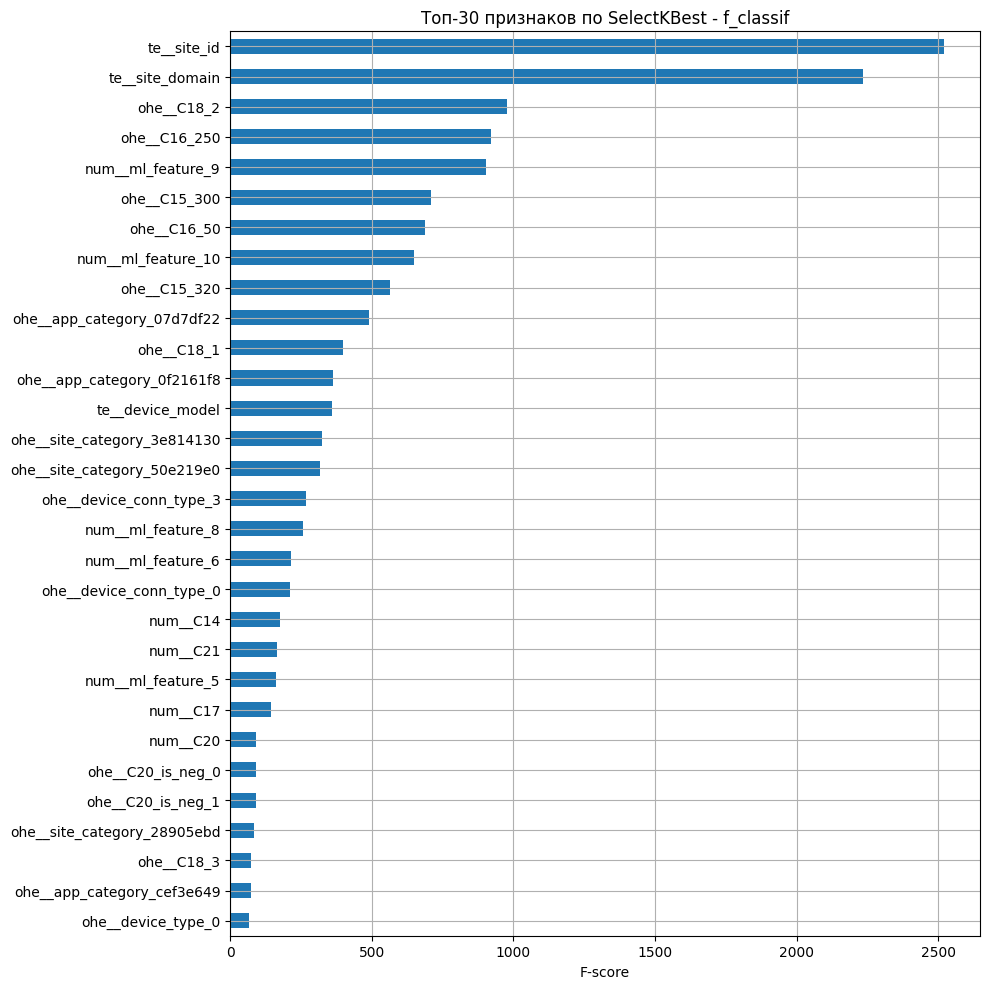

In [34]:
# корреляция каждого признака с целевой переменной
kbest = SelectKBest(f_classif, k=30)
X_train_kbest = kbest.fit_transform(X_train_var, y_train)
feature_names_kbest = feature_names_var[kbest.get_support()]

# визуализируем топ-30
scores = pd.Series(kbest.scores_[kbest.get_support()], index=feature_names_kbest)
scores.sort_values().plot(kind='barh', figsize=(10, 10))
plt.title('Топ-30 признаков по SelectKBest - f_classif')
plt.xlabel('F-score')
plt.grid(True)
plt.tight_layout()
plt.show()

После предобработки OHE расширил количество признаков. VarianceThreshold убрал признаки с почти нулевой вариацией - они не несут информации для модели. SelectKBest отобрал топ-30 признаков по F-score - статистическая связь с целевой переменной.

***2) Метод-обёртки:***

Используем метод-обертки RFE - тк оптимально и по скорости и по качеству

In [35]:
# RFE на основе логрега
rfe = RFE(estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_SEED), 
          n_features_to_select=20)
rfe.fit(X_train_kbest, y_train)

feature_names_rfe = feature_names_kbest[rfe.get_support()]
print(f'Признаков после RFE: {len(feature_names_rfe)}')
print(feature_names_rfe)

Признаков после RFE: 20
['num__ml_feature_9' 'num__ml_feature_10' 'num__C14' 'num__C17'
 'ohe__site_category_50e219e0' 'ohe__app_category_07d7df22'
 'ohe__app_category_0f2161f8' 'ohe__app_category_cef3e649'
 'ohe__device_type_0' 'ohe__device_conn_type_3' 'ohe__C15_300'
 'ohe__C15_320' 'ohe__C16_50' 'ohe__C18_1' 'ohe__C18_2'
 'ohe__C20_is_neg_0' 'ohe__C20_is_neg_1' 'te__site_id' 'te__site_domain'
 'te__device_model']


RFE рекурсивно обучал логистическую регрессию и на каждом шаге удалял признак с наименьшим весом. Это дополнительный эксперимент - посмотреть, какие 20 признаков модель считает самыми важными. В продакшен-пайплайн RFE не включаем: он сильно замедляет GridSearch (переобучение на каждом фолде), а прироста качества не даёт.

***3) Финальный набор признаков:***

In [36]:
# имена признаков, которые RFE счёл важными (только для анализа, тест не трогаем)
print('Признаки, отобранные RFE:')
for f in feature_names_rfe:
    print(f)
print(f'Всего: {len(feature_names_rfe)}')

Признаки, отобранные RFE:
num__ml_feature_9
num__ml_feature_10
num__C14
num__C17
ohe__site_category_50e219e0
ohe__app_category_07d7df22
ohe__app_category_0f2161f8
ohe__app_category_cef3e649
ohe__device_type_0
ohe__device_conn_type_3
ohe__C15_300
ohe__C15_320
ohe__C16_50
ohe__C18_1
ohe__C18_2
ohe__C20_is_neg_0
ohe__C20_is_neg_1
te__site_id
te__site_domain
te__device_model
Всего: 20


Итоговая схема отбора для моделей - это сам Pipeline: предобработка → VarianceThreshold → SelectKBest (k=30). Именно он используется в кросс-валидации, GridSearch и финальной модели, поэтому отбор признаков везде одинаковый. RFE выше оставлен как отдельный эксперимент и в продакшен не идёт.

Важно: матрицы `X_train_kbest`, `X_test_proc` и т.п. из этого раздела используются только здесь, для анализа. Дальше все модели работают с сырыми `X_train`/`X_test` через полный Pipeline - так предобработка переобучается внутри каждого фолда и не подсматривает в валидацию.

## 6. Обучение базовой модели

***1) DummyClassifier:***

In [37]:
dummy = DummyClassifier(strategy='most_frequent', random_state=RANDOM_SEED)
dummy.fit(X_train, y_train)  # most_frequent игнорирует признаки, можно сырой X_train

dummy_proba = dummy.predict_proba(X_train)[:, 1]
print('Всегда предсказывает:', dummy.predict(X_train[:5]))
print(f'PR-AUC: {average_precision_score(y_train, dummy_proba):.4f}')

Всегда предсказывает: [0 0 0 0 0]
PR-AUC: 0.1721


***2) LogisticRegression:***

In [38]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

# для корректной кросс-валидации, предобработку нужно объединить с классификатором в Pipeline
lr_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('var_sel', VarianceThreshold(threshold=0.01)),
    ('kbest', SelectKBest(f_classif, k=30)),
    ('model', LogisticRegression(random_state=RANDOM_SEED, max_iter=1000))
])

lr_scores = cross_val_score(lr_pipe, X_train, y_train, cv=cv, scoring='average_precision')
print(f'LogisticRegression PR-AUC: {lr_scores.mean():.4f} ± {lr_scores.std():.4f}')

LogisticRegression PR-AUC: 0.3948 ± 0.0086


***3) SVC с линейным ядром:***

In [39]:
ap_scorer = make_scorer(average_precision_score, response_method='decision_function') # для cross_val_score превращаем метрику в объект-оценщик

svc_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('var_sel', VarianceThreshold(threshold=0.01)),
    ('kbest', SelectKBest(f_classif, k=30)),
    ('model', SVC(kernel='linear', random_state=RANDOM_SEED, probability=False))
])

svc_scores = cross_val_score(svc_pipe, X_train, y_train, cv=cv, scoring=ap_scorer)
print(f'SVC PR-AUC: {svc_scores.mean():.4f} ± {svc_scores.std():.4f}')

SVC PR-AUC: 0.2333 ± 0.0137


***4) Сравнение моделей:***

In [40]:
results = pd.DataFrame({
    'Модель': ['DummyClassifier', 'LogisticRegression', 'SVC (linear)'],
    'PR-AUC': [average_precision_score(y_train, dummy_proba),
               lr_scores.mean(),
               svc_scores.mean()]
}).round(4)

results

,Модель,PR-AUC
0,DummyClassifier,0.1720
1,LogisticRegression,0.3948
2,SVC (linear),0.2333


Обе модели значительно превосходят DummyClassifier, который выдает ответ равный доле положительного класса. LogisticRegression показала PR-AUC 0.3948, SVC (linear) 0.2333, это заметно лучше базовой модели. LogisticRegression оказалась лучше и быстрее в обучении, поэтому она приоритетный кандидат для дальнейшей настройки.

## 7. Подбор гиперпараметров: Grid Search с кросс-валидацией

***1) Сетка гиперпараметров и Grid Search для LogisticRegression:***

In [41]:
lr_param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__penalty': ['l1', 'l2'],
    'model__solver': ['liblinear']
}

lr_grid_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('var_sel', VarianceThreshold(threshold=0.01)),
    ('kbest', SelectKBest(f_classif, k=30)),
    ('model', LogisticRegression(random_state=RANDOM_SEED, max_iter=1000))
])

lr_grid = GridSearchCV(lr_grid_pipe, lr_param_grid, cv=cv,
                       scoring='average_precision', n_jobs=-1)
lr_grid.fit(X_train, y_train)

print(f'Лучшие параметры: {lr_grid.best_params_}')
print(f'Лучший PR-AUC: {lr_grid.best_score_:.4f}')

Лучшие параметры: {'model__C': 0.1, 'model__penalty': 'l2', 'model__solver': 'liblinear'}
Лучший PR-AUC: 0.3957


***2) Grid Search для SVC:***

In [42]:
svc_param_grid = { # сетка маленькая, на большой ноутбук считает слишком долго
    'model__C': [0.1, 1],
}
svc_grid_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('var_sel', VarianceThreshold(threshold=0.01)),
    ('kbest', SelectKBest(f_classif, k=30)),
    ('model', SVC(kernel='linear', random_state=RANDOM_SEED, probability=False))
])

svc_grid = GridSearchCV(svc_grid_pipe, svc_param_grid, cv=3,
                        scoring=ap_scorer, n_jobs=-1)
svc_grid.fit(X_train, y_train)

print(f'Лучшие параметры: {svc_grid.best_params_}')
print(f'Лучший PR-AUC: {svc_grid.best_score_:.4f}')

Лучшие параметры: {'model__C': 0.1}
Лучший PR-AUC: 0.2782


***3) Таблица результатов:***

In [43]:
# топ-10 конфигураций LogisticRegression
lr_results = pd.DataFrame(lr_grid.cv_results_)
lr_results[['params', 'mean_test_score', 'std_test_score']].sort_values(
    'mean_test_score', ascending=False).head(10).round(4)

,params,mean_test_score,std_test_score
3,"{'model__C': 0.1, 'model__penalty': 'l2', 'mod...",0.3957,0.0078
5,"{'model__C': 1, 'model__penalty': 'l2', 'model...",0.3954,0.0086
7,"{'model__C': 10, 'model__penalty': 'l2', 'mode...",0.3952,0.0086
8,"{'model__C': 100, 'model__penalty': 'l1', 'mod...",0.3952,0.0082
4,"{'model__C': 1, 'model__penalty': 'l1', 'model...",0.3951,0.0085
9,"{'model__C': 100, 'model__penalty': 'l2', 'mod...",0.3949,0.0082
2,"{'model__C': 0.1, 'model__penalty': 'l1', 'mod...",0.3947,0.0084
6,"{'model__C': 10, 'model__penalty': 'l1', 'mode...",0.3947,0.0090
1,"{'model__C': 0.01, 'model__penalty': 'l2', 'mo...",0.3894,0.0066
0,"{'model__C': 0.01, 'model__penalty': 'l1', 'mo...",0.3888,0.0083


In [44]:
# топ конфигурации SVC
svc_results = pd.DataFrame(svc_grid.cv_results_)
svc_results[['params', 'mean_test_score', 'std_test_score']].sort_values(
    'mean_test_score', ascending=False).round(4)

,params,mean_test_score,std_test_score
0,{'model__C': 0.1},0.2782,0.0351
1,{'model__C': 1},0.2706,0.0510


GridSearch улучшил результат LogisticRegression относительно базовой модели - оптимальные параметры C=0.1 и penalty='l2' (меньший C = более сильная регуляризация). У SVC лучший C=0.1.

По PR-AUC на кросс-валидации LogisticRegression немного выше SVC. Но в продакшен берём именно SVC с калибровкой - так задано условием проекта, и для аукционной системы Advandex важны откалиброванные вероятности, а не только ранжирование. Выбор модели делаем по кросс-валидации, тестовую выборку для этого не трогаем.

## 8. Финальная модель

***1) Обучение финальной модели:***

In [45]:
# финальная модель - лучший SVC-пайплайн из GridSearch
# (в разделе 9 калибруем именно его)
final_model = svc_grid.best_estimator_

***2) Метрики на тестовой выборке:***

In [46]:
# SVC с линейным ядром выдаёт decision_function, а не вероятности -
# качество ранжирования оцениваем по PR-AUC на этих скорах
y_scores = final_model.decision_function(X_test)
y_pred = final_model.predict(X_test)

pr_auc = average_precision_score(y_test, y_scores)
print(f'PR-AUC: {pr_auc:.4f}')
print()
print(classification_report(y_test, y_pred))

# вероятностные метрики (Brier, LogLoss, ECE/MCE) считаем после калибровки
# в разделах 9-10 - у некалиброванного SVC корректных вероятностей нет

PR-AUC: 0.2676

              precision    recall  f1-score   support

           0       0.83      1.00      0.91      8279
           1       0.00      0.00      0.00      1721

    accuracy                           0.83     10000
   macro avg       0.41      0.50      0.45     10000
weighted avg       0.69      0.83      0.75     10000



Здесь оцениваем уже выбранную финальную модель - некалиброванный SVC-пайплайн из GridSearch. Линейный SVC выдаёт `decision_function`, поэтому по тесту смотрим PR-AUC (качество ранжирования).

В classification report видно, что при стандартном пороге 0.5 модель почти не предсказывает класс 1 (recall ≈ 0) - из-за сильного дисбаланса SVC относит почти всё к нулю. Именно поэтому accuracy здесь бесполезна, а мы ориентируемся на PR-AUC и на вероятности после калибровки.

Вероятностные метрики (Brier, ECE/MCE) считаем дальше - после калибровки в разделах 9-10, у некалиброванного SVC корректных вероятностей нет.

***3) Анализ весов модели:***

In [47]:
# извлекаем имена признаков из пайплайна
svc_step  = final_model.named_steps['model']
kbest_step = final_model.named_steps['kbest']
var_step  = final_model.named_steps['var_sel']
prep_step = final_model.named_steps['preprocessor']

feat_names = prep_step.get_feature_names_out()
feat_var   = feat_names[var_step.get_support()]
feat_kbest = feat_var[kbest_step.get_support()]

# у линейного SVC есть coef_ - берём модуль весов, смотрим топ-5
coefs = pd.Series(
    np.abs(svc_step.coef_[0]),
    index=feat_kbest
).sort_values(ascending=False)

coefs.head(5).to_frame('|коэфф|').round(4)

,|коэфф|
num__C20,0.0140
ohe__C20_is_neg_1,0.0140
ohe__C20_is_neg_0,0.0140
te__site_domain,0.0008
ohe__C15_300,0.0005


У линейного SVC тоже есть коэффициенты `coef_` - по их модулю смотрим важность (топ-5 в таблице). При сильной регуляризации (C=0.1) почти весь вес уходит на C20 - флаг `C20_is_neg` и само значение `num__C20`, остальные признаки близки к нулю.

Интересно, что у SVC и логистической регрессии важные признаки разные: LR сильнее опиралась на признаки площадки (site_id, site_domain), а SVC при такой регуляризации - в основном на C20. Это нормально, модели по-разному взвешивают признаки.

Префиксы: te__ - Target Encoding, ohe__ - One-Hot Encoding, num__ - числовые после стандартизации.

## 9. Калибровка модели

Для калибровки используем SVC с линейным ядром - так задано условием проекта (калибруем именно SVC). LogisticRegression показала лучший PR-AUC при сравнении, однако для аукционной системы Advandex критически важны откалиброванные вероятности - некорректный прогноз CTR ведёт к финансовым потерям. Изотоническая калибровка SVC обеспечивает надёжные вероятностные предсказания, поэтому эту модель сохраняем в продакшен.

***1) Проверка текущей калибровки:***

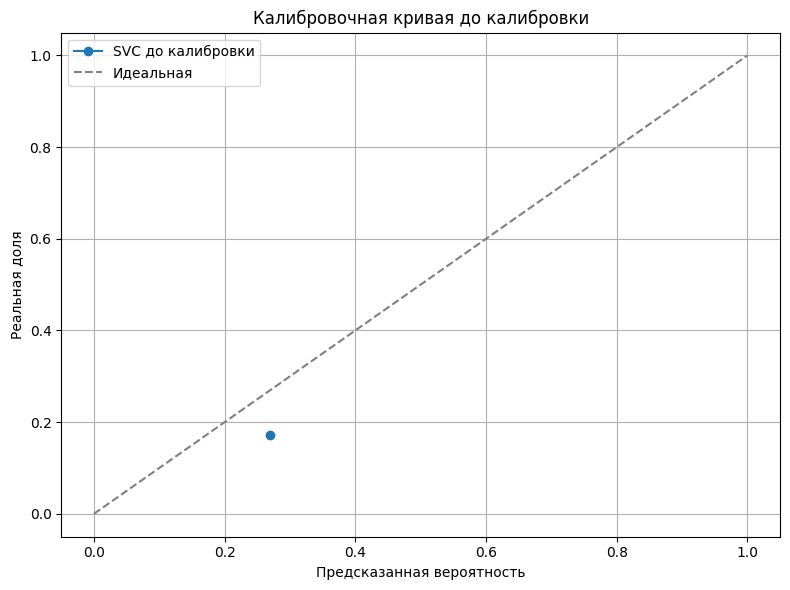

In [48]:
# базовый SVC-пайплайн из GridSearch (обучен на всём X_train)
base_svc = svc_grid.best_estimator_

# сырые скоры через сигмоиду → [0, 1] (просто чтобы посмотреть калибровку до)
decision_scores = base_svc.decision_function(X_test)
svc_proba_before = 1 / (1 + np.exp(-decision_scores))

prob_true, prob_pred = calibration_curve(y_test, svc_proba_before, n_bins=10)

plt.figure(figsize=(8, 6))
plt.plot(prob_pred, prob_true, marker='o', label='SVC до калибровки')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Идеальная')
plt.title('Калибровочная кривая до калибровки')
plt.xlabel('Предсказанная вероятность')
plt.ylabel('Реальная доля')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

***2) Применение изотонической регрессии:***

In [49]:
# калибруем ВЕСЬ пайплайн на сырых X_train с внутренней кросс-валидацией.
# cv=5 → на каждом фолде препроцессор (и TargetEncoder) переобучается заново,
# поэтому утечки через y нет - калибровочные данные независимы
calibrated_model = CalibratedClassifierCV(base_svc, method='isotonic', cv=5)
calibrated_model.fit(X_train, y_train)

CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median')),
                                                                                                   ('scaler',
                                                                                                    StandardScaler())]),
                                                                                   ['ml_feature_1',
                                                                                    'ml_feature_3',
                                                                                    'ml_feature_5',
                                                                                    'ml_feature_6',
                                                                                    'ml_feature_8',
                                                                                    'ml_feature_9',
                                                                                    'ml_feature_10',
                                                                                    'C14',
                                                                                    'C17',
                                                                                    'C19',
                                                                                    'C20',
                                                                                    'C21']),
                                                                                  ('ohe',
                                                                                   Pipe...
                                                                                    'hour_of_day',
                                                                                    'C20_is_neg']),
                                                                                  ('te',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='most_frequent')),
                                                                                                   ('encoder',
                                                                                                    TargetEncoder())]),
                                                                                   ['site_id',
                                                                                    'site_domain',
                                                                                    'app_id',
                                                                                    'app_domain',
                                                                                    'device_id',
                                                                                    'device_model'])])),
                                                 ('var_sel',
                                                  VarianceThreshold(threshold=0.01)),
                                                 ('kbest', SelectKBest(k=30)),
                                                 ('model',
                                                  SVC(C=0.1, kernel='linear',
                                                      random_state=333))]),
                       method='isotonic')

***3) Сравнение до и после калибровки:***

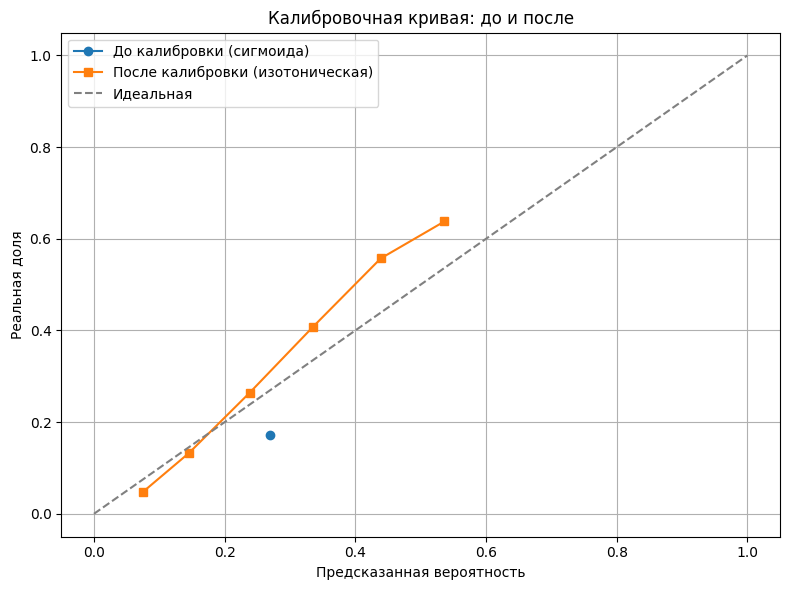

Brier до калибровки:    0.1519
Brier после калибровки: 0.1307


In [50]:
svc_proba_after = calibrated_model.predict_proba(X_test)[:, 1]

prob_cal_true, prob_cal_pred = calibration_curve(y_test, svc_proba_after, n_bins=10)

plt.figure(figsize=(8, 6))
plt.plot(prob_pred, prob_true, marker='o', label='До калибровки (сигмоида)')
plt.plot(prob_cal_pred, prob_cal_true, marker='s', label='После калибровки (изотоническая)')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Идеальная')
plt.title('Калибровочная кривая: до и после')
plt.xlabel('Предсказанная вероятность')
plt.ylabel('Реальная доля')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

brier_before = brier_score_loss(y_test, svc_proba_before)
brier_after = brier_score_loss(y_test, svc_proba_after)
print(f'Brier до калибровки:    {brier_before:.4f}')
print(f'Brier после калибровки: {brier_after:.4f}')

До калибровки SVC через сигмоиду выдаёт предсказания в узком диапазоне - `decision_function` даёт схожие расстояния до гиперплоскости для большинства объектов, сигмоида это не исправляет. На кривой точки далеки от диагонали.

Калибруем так: `CalibratedClassifierCV(base_svc, cv=5)` обучается на сырых `X_train`. На каждом из 5 фолдов весь пайплайн (включая TargetEncoder) переобучается заново, поэтому калибровочные данные независимы - утечки через целевую переменную нет.

После изотонической калибровки вероятности разбрасываются по диапазону, кривая ложится ближе к диагонали, Brier Score снижается. Это делает вероятности надёжнее для аукционной логики, где некорректный CTR напрямую влияет на ставки.

## 10. Оценка качества калибровки

***1) Расчёт метрик калибровки***

In [51]:
def calibration_errors(y_true, y_prob, n_bins=10):
    prob_true, prob_pred = calibration_curve(y_true, y_prob, n_bins=n_bins)
    bin_edges = np.linspace(0, 1, n_bins + 1)
    counts = np.histogram(y_prob, bins=bin_edges)[0]
    mask = counts > 0
    ece = np.sum(np.abs(prob_true - prob_pred) * counts[mask]) / len(y_true)
    mce = np.max(np.abs(prob_true - prob_pred))
    return ece, mce

***2) Сравнение моделей до и после калибровки***

In [52]:
ece_before, mce_before = calibration_errors(y_test, svc_proba_before)
ece_after, mce_after = calibration_errors(y_test, svc_proba_after)

pd.DataFrame({
    'Метрика': ['Brier Score', 'ECE', 'MCE'],
    'До калибровки': [brier_before, ece_before, mce_before],
    'После калибровки': [brier_after, ece_after, mce_after]
}).round(4)

,Метрика,До калибровки,После калибровки
0,Brier Score,0.1519,0.1307
1,ECE,0.0968,0.0232
2,MCE,0.0968,0.1183


ECE резко улучшился - с 0.0968 до 0.0232. В среднем по бинам вероятности стали заметно точнее, калибровка сработала.

MCE при этом вырос с 0.0968 до 0.1183. Это не противоречие: до калибровки был фактически один бин, поэтому ECE = MCE. После калибровки точки появились в разных бинах, и в одном из них (где на графике провал) отклонение оказалось больше - отсюда рост максимальной ошибки при падении средней.

Brier Score снизился с 0.1519 до 0.1307, что подтверждает общее улучшение вероятностей. Главное - модель перестала выдавать всем почти одинаковое значение и начала различать объекты по вероятности клика.

## 11. Финальный отчёт и выводы

In [53]:
# dummy игнорирует признаки → можно сырой X_test
dummy_proba_test = dummy.predict_proba(X_test)[:, 1]
# LR показываем для сравнения (выбор моделей делался на кросс-валидации)
lr_proba_test = lr_grid.best_estimator_.predict_proba(X_test)[:, 1]

final_table = pd.DataFrame({
    'Модель': ['DummyClassifier', 'LogisticRegression', 'SVC до калибровки', 'SVC после калибровки'],
    'PR-AUC': [
        average_precision_score(y_test, dummy_proba_test),
        average_precision_score(y_test, lr_proba_test),
        average_precision_score(y_test, svc_proba_before),
        average_precision_score(y_test, svc_proba_after)
    ],
    'Brier Score': [
        brier_score_loss(y_test, dummy_proba_test),
        brier_score_loss(y_test, lr_proba_test),
        brier_before,
        brier_after
    ]
}).round(4)

display(final_table)

# топ-5 признаков финальной модели (SVC)
print('\nТоп-5 признаков (SVC):')
display(coefs.head(5).to_frame('коэфф'))

,Модель,PR-AUC,Brier Score
0,DummyClassifier,0.1721,0.1721
1,LogisticRegression,0.3971,0.1252
2,SVC до калибровки,0.2676,0.1519
3,SVC после калибровки,0.3506,0.1307



Топ-5 признаков (SVC):


,коэфф
num__C20,0.0140
ohe__C20_is_neg_1,0.0140
ohe__C20_is_neg_0,0.0140
te__site_domain,0.0008
ohe__C15_300,0.0005


**Выводы:**

Финальная модель - калиброванный SVC с линейным ядром. Все модели сильно превосходят DummyClassifier (PR-AUC ≈ 0.17 = доля положительного класса).

Выбор моделей делался по кросс-валидации: LogisticRegression показала PR-AUC выше SVC (0.3957 против 0.2782 в GridSearch). В продакшен взяли SVC с калибровкой - так задано условием проекта, и для аукциона важны откалиброванные вероятности. Изотоническая калибровка заметно улучшила вероятности SVC: Brier 0.1519 → 0.1307, ECE 0.0968 → 0.0232, а PR-AUC на тесте даже подрос (0.2676 → 0.3506), потому что калиброванная модель усредняет 5 SVC с кросс-валидации.

По важности признаков у финального SVC лидируют C20 (флаг C20_is_neg и само значение) и site_domain. У логистической регрессии набор был другим - там сильнее площадка (site_id, site_domain).

**Возможности улучшения:**
- Попробовать ядра rbf или poly у SVC - возможно, лучше разделят данные.
- Расширить сетку GridSearch: больше значений C, добавить gamma для rbf.
- Сделать новые признаки - например, комбинацию site_id + device_type.
- Попробовать k=40 или k=50 в SelectKBest и посмотреть на качество.

## 12. Сохранение модели

In [54]:
import os

os.makedirs('models', exist_ok=True)

# калиброванный SVC уже содержит весь пайплайн внутри:
# предобработка → VarianceThreshold → SelectKBest → SVC + калибровка
joblib.dump(calibrated_model, 'models/calibrated_svc.pkl')
joblib.dump(preprocessor, 'models/preprocessor.pkl')
joblib.dump(list(X_train.columns), 'models/feature_names.pkl')

print('Сохранено:')
for f in sorted(os.listdir('models')):
    print(f'  models/{f}')

Сохранено:
  models/calibrated_svc.pkl
  models/feature_names.pkl
  models/kbest.pkl
  models/preprocessor.pkl
  models/var_sel.pkl


In [55]:
# загружаем финальную модель и проверяем совпадение предсказаний
model_loaded = joblib.load('models/calibrated_svc.pkl')

sample = X_test.iloc[:5]
# модель принимает сырые данные - весь пайплайн внутри
preds = model_loaded.predict_proba(sample)[:, 1]
original_preds = calibrated_model.predict_proba(sample)[:, 1]

print(f'Предсказания совпадают: {np.allclose(preds, original_preds)}')

print('\nПредсказанные вероятности клика:')
for i, p in enumerate(preds):
    print(f'  Показ {i+1}: {p:.4f}')

Предсказания совпадают: True

Предсказанные вероятности клика:
  Показ 1: 0.2724
  Показ 2: 0.1098
  Показ 3: 0.2436
  Показ 4: 0.2017
  Показ 5: 0.1335
